In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.datasets import fetch_kddcup99
from sklearn.cluster import KMeans

SEED = 42
rng = np.random.default_rng(SEED)

k = 15
m_values = [5, 10, 15, 20, 25]

In [ ]:
kdd = fetch_kddcup99(subset=None, as_frame=True)
data = kdd.data.copy()

categorical_columns = ["protocol_type", "service", "flag"]

numeric_data = data.drop(columns=categorical_columns).astype(np.float32)
categorical_data_one_hot_enc = pd.get_dummies(data[categorical_columns], dtype=np.float32)

D_df = pd.concat([numeric_data, categorical_data_one_hot_enc], axis=1)
D_df = D_df.loc[:, D_df.nunique(dropna=False) > 1]
D_df = (D_df - D_df.min()) / (D_df.max() - D_df.min())
D = D_df.to_numpy(dtype=np.float32)

n, d = D.shape

print("Number of rows (n):", n)
print("Number of columns (d):", d)
print("Shape of D:", D.shape)

Number of rows (n): 494021
Number of columns (d): 116
Shape of D: (494021, 116)


In [ ]:
def calculate_cost(X, centers, batch_size=50000):
    total_cost = 0.0
    centers = np.asarray(centers, dtype=np.float64)
    center_norms = np.sum(centers**2, axis=1)

    for i in range(0, len(X), batch_size):
        curent_grp = X[i:i + batch_size].astype(np.float64)
        distances = (np.sum(curent_grp**2, axis=1, keepdims=True) + center_norms - 2 * curent_grp @ centers.T)
        total_cost = total_cost + np.maximum(distances.min(axis=1), 0).sum()

    return total_cost


def reconstruct_centers(D, labels, k):
    points_in_cluster = np.bincount(labels, minlength=k)
    if np.any(points_in_cluster == 0):
        raise ValueError("An empty cluster was found")

    sums = np.zeros((k, D.shape[1]), dtype=np.float64)

    for j in range(k):
        sums[j] = D[labels == j].sum(axis=0, dtype=np.float64)

    return sums / points_in_cluster[:, None]


def gaussian_projection(m, d, seed):
    r = np.random.default_rng(seed)
    return (r.standard_normal((m, d)) / np.sqrt(m)).astype(np.float32)

In [ ]:
start_time = time.perf_counter()

kmeans_D = KMeans(n_clusters=15, n_init=5, random_state=SEED)

kmeans_D.fit(D)

time_D = time.perf_counter() - start_time

B = kmeans_D.cluster_centers_
C_D = kmeans_D.labels_

cost_D_B = calculate_cost(D, B)
print("Cost(D, B) :", cost_D_B)
print("Wall-clock time :", time_D, "seconds")

Cost(D, B) : 53500.90674492283
Wall-clock time : 28.295106885001587 seconds


In [ ]:
results = []
saved_runs = []

for each_m in m_values :
    for i in range(0,5) :

        A = gaussian_projection(each_m, d, seed=SEED + 1000*each_m + i)
        start_time = time.perf_counter()
        E = D @ A.T
        kmeans_E = KMeans(n_clusters=15, n_init=5, random_state=SEED + 100 * each_m + i)
        kmeans_E.fit(E)

        projection_kmeans_time = time.perf_counter() - start_time
        assign_E = kmeans_E.labels_
        B_cap = reconstruct_centers(D, assign_E, k)

        cost_cap = calculate_cost(D, B_cap)
        ratio_cost = cost_cap / cost_D_B

        results.append({
            "m": each_m,
            "repetition": i + 1,
            "cost_cap": cost_cap,
            "ratio_cost": ratio_cost,
            "time": projection_kmeans_time
        })
        saved_runs.append({
            "m": each_m,
            "repetition": i+1,
            "A": A,
            "projected_centers": kmeans_E.cluster_centers_
        })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

 m  repetition     cost_cap  ratio_cost     time
 5           1 83828.217424    1.566856 5.570474
 5           2 66536.817252    1.243658 5.185970
 5           3 77754.720733    1.453335 5.353254
 5           4 66810.138321    1.248766 5.736300
 5           5 65907.439714    1.231894 6.158678
10           1 54269.589204    1.014368 5.735116
10           2 54684.573384    1.022124 6.459654
10           3 55639.191596    1.039967 5.115592
10           4 60657.935354    1.133774 6.063675
10           5 53517.433027    1.000309 5.117711
15           1 54422.051012    1.017217 7.317527
15           2 53895.896655    1.007383 5.430839
15           3 53553.664845    1.000986 7.354724
15           4 52696.768403    0.984970 8.498300
15           5 55282.572944    1.033302 5.873752
20           1 51607.245483    0.964605 7.571527
20           2 58397.811604    1.091529 6.529636
20           3 51558.226398    0.963689 6.395043
20           4 54136.163925    1.011874 9.461764
20           5 52003

For m = 5 the cost ratio is the worst. For m>=10 mean ratio is close to 1 but doesn't decrease steadily with m. The difference between the m values are comparable to the run to run spread, so increasing m beyond about 10 gives no clear further gain.
Some ratios fall below 1, meaning B_cap has a lower cost than the baseline B. The global optimum cannot be beaten, so this only shows that k-means on D found a local optimum, and the projected run happened to land on a better one.


In [ ]:
summary_b = results_df.groupby("m").agg(
    Mean_Cost=("cost_cap", "mean"),
    Mean_Ratio=("ratio_cost", "mean"),
    Min_Ratio=("ratio_cost", "min"),
    Max_Ratio=("ratio_cost", "max")).reset_index()

print(summary_b.to_string(index=False))

 m    Mean_Cost  Mean_Ratio  Min_Ratio  Max_Ratio
 5 72167.466689    1.348902   1.231894   1.566856
10 55753.744513    1.042108   1.000309   1.133774
15 53970.190772    1.008772   0.984970   1.033302
20 53540.650204    1.000743   0.963689   1.091529
25 53904.261406    1.007539   0.981156   1.035513


In [ ]:
results_c = []

for each in saved_runs:
    cur_m = each["m"]
    cur_rep = each["repetition"]

    A = each["A"].astype(np.float64)

    projected_centers = each["projected_centers"]

    A_pinv = np.linalg.pinv(A)
    B_plus = projected_centers @ A_pinv.T
    cost_plus = calculate_cost(D, B_plus)
    ratio_plus = cost_plus / cost_D_B

    results_c.append({
        "m": cur_m,
        "repetition": cur_rep,
        "cost_plus": cost_plus,
        "ratio_plus": ratio_plus
    })

results_c_df = pd.DataFrame(results_c)

comparison_c = results_df.merge(results_c_df, on=["m", "repetition"])
print(comparison_c.to_string(index=False))

 m  repetition     cost_cap  ratio_cost     time    cost_plus  ratio_plus
 5           1 83828.217424    1.566856 5.570474 4.387405e+06   82.006177
 5           2 66536.817252    1.243658 5.185970 4.345873e+06   81.229886
 5           3 77754.720733    1.453335 5.353254 4.287690e+06   80.142382
 5           4 66810.138321    1.248766 5.736300 4.296112e+06   80.299790
 5           5 65907.439714    1.231894 6.158678 4.225130e+06   78.973061
10           1 54269.589204    1.014368 5.735116 4.217062e+06   78.822251
10           2 54684.573384    1.022124 6.459654 4.003252e+06   74.825876
10           3 55639.191596    1.039967 5.115592 3.850410e+06   71.969068
10           4 60657.935354    1.133774 6.063675 4.068132e+06   76.038555
10           5 53517.433027    1.000309 5.117711 4.154574e+06   77.654277
15           1 54422.051012    1.017217 7.317527 3.781061e+06   70.672834
15           2 53895.896655    1.007383 5.430839 3.930755e+06   73.470820
15           3 53553.664845    1.00098

In [ ]:
summary_c = comparison_c.groupby("m").agg(
    Mean_Ratio_Bhat=("ratio_cost", "mean"),
    Mean_Ratio_Bplus=("ratio_plus", "mean")).reset_index()

print(summary_c.to_string(index=False))

 m  Mean_Ratio_Bhat  Mean_Ratio_Bplus
 5         1.348902         80.530259
10         1.042108         75.862005
15         1.008772         73.147331
20         1.000743         68.166503
25         1.007539         65.163055


The results show that B_cap outperforms B+ for all projection dimensions. The mean cost ratio for B_cap is close to 1 for m>=10, whereas for m=5 its noticeably higher at approximately 1.35.

This happens because pseudo-inverse reconstruction can't recover information lost during dimensionality reduction. Whereas, B_cap is calculated by averaging original data points within each projected cluster, preserving the original space cluster information. <br>

I would use B_cap instead of B+ as it consistently produces much lower clustering costs and ratios closer to 1 across all values of m.

Time to compute E + Time to run k-means on E
m
5     5.600935
10    5.698349
15    6.895029
20    7.176203
25    8.096560
Name: time, dtype: float64


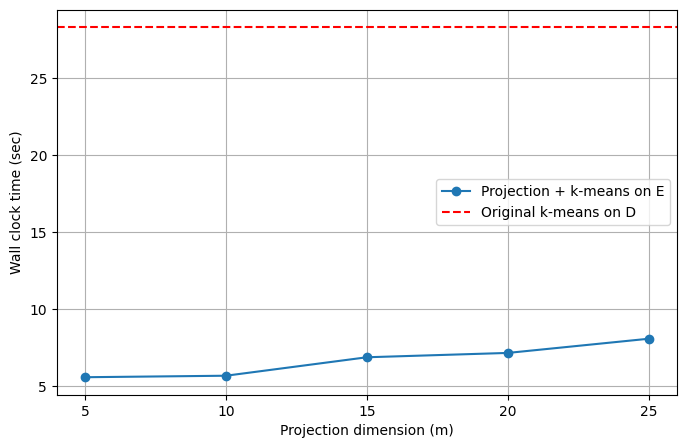

In [ ]:
time_summary = results_df.groupby("m")["time"].mean()

print("Time to compute E + Time to run k-means on E")
print(time_summary)

plt.figure(figsize=(8, 5))

plt.plot(time_summary.index,
    time_summary.values,
    marker="o",
    label="Projection + k-means on E")

plt.axhline(y=time_D,
    linestyle="--",
    color="red",
    label="Original k-means on D")

plt.xlabel("Projection dimension (m)")
plt.ylabel("Wall clock time (sec)")
plt.xticks(m_values)
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
pair_i = []
pair_l = []

pair_rng = np.random.default_rng(SEED + 1)

while len(pair_i) < 10000 :
    i = pair_rng.integers(0, n)
    l = pair_rng.integers(0, n)
    if i != l and np.any(D[i] != D[l]):
        pair_i.append(i)
        pair_l.append(l)

pair_i = np.array(pair_i)
pair_l = np.array(pair_l)

differences = (D[pair_i].astype(np.float64) - D[pair_l].astype(np.float64))

original_distances = np.sum(differences**2, axis=1)

print("Number of valid pairs:", len(pair_i))

Number of valid pairs: 10000


In [ ]:
distance_ratios = {}

for each in m_values:
    A = gaussian_projection(each, d, seed=SEED + 5000 + each).astype(np.float64)
    projected_differences = differences @ A.T
    projected_distances = np.sum(projected_differences**2, axis=1)
    ratios = projected_distances / original_distances
    distance_ratios[each] = ratios

In [ ]:
original_centers = reconstruct_centers(D, C_D, k)

W = np.zeros((d, d), dtype=np.float64)

batch_size = 25000

for i in range(0, n, batch_size) :
    end = min(i + batch_size, n)
    residuals = (D[i:end].astype(np.float64) - original_centers[C_D[i:end]])

    W = W + residuals.T @ residuals

cost_original_partition = np.trace(W)
print("Cost_D(C_D):", cost_original_partition)

Cost_D(C_D): 53498.03538292972


In [ ]:
clustering_ratios = {}

for each in m_values:
    ratios = []
    for rep in range(20):
        A = gaussian_projection(each, d, seed=SEED + 100000 + 100*each + rep).astype(np.float64)
        projected_cost = np.trace(A @ W @ A.T)
        ratio = projected_cost / cost_original_partition
        ratios.append(ratio)

    clustering_ratios[each] = np.array(ratios)

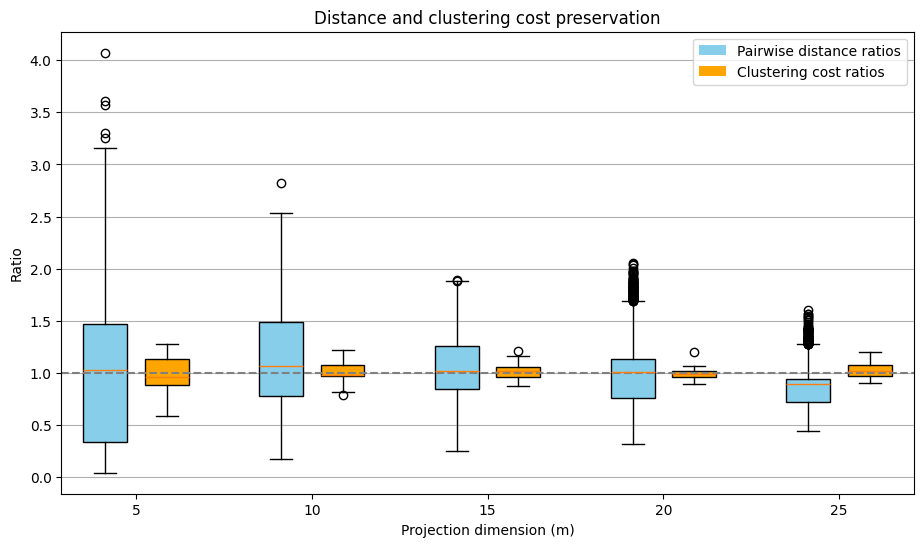

In [ ]:
figure, ax = plt.subplots(figsize=(11, 6))
positions_distance = np.arange(len(m_values)) * 2
positions_clustering = positions_distance + 0.7

bp1 = ax.boxplot(
    [distance_ratios[m] for m in m_values],
    positions=positions_distance,
    widths=0.5,
    patch_artist=True)

bp2 = ax.boxplot(
    [clustering_ratios[m] for m in m_values],
    positions=positions_clustering,
    widths=0.5,
    patch_artist=True)

for i in bp1["boxes"] :
    i.set_facecolor("skyblue")
for i in bp2["boxes"] :
    i.set_facecolor("orange")

ax.set_xticks(positions_distance + 0.35)
ax.set_xticklabels(m_values)

ax.set_xlabel("Projection dimension (m)")
ax.set_ylabel("Ratio")
ax.set_title("Distance and clustering cost preservation")
ax.axhline(y=1, linestyle="--", color="gray")

from matplotlib.patches import Patch

ax.legend(handles=[Patch(facecolor="skyblue", label="Pairwise distance ratios"), Patch(facecolor="orange", label="Clustering cost ratios")])

plt.grid(True, axis="y")
plt.show()

The box plots show that clustering cost ratios(orange) have a smaller spread that the pairwaise distance ratios (blue) for all m. <br>


Pairwise distance ratios show considerable variation at smaller projection dimensions. As m increases, their spread generally decreases, indicating better distance preservation. However, some outliers remain, and the ratios are not always centred exactly at 1. <br>


On other hand, clustering cost ratios remain consistently concentrated around 1, with relatively small variation, particularly for larger values of m. <br>

A ratio close to 1 indicates that random projection preserves the original squared distance or clustering cost accurately. A ratio greater than 1 indicates an increase after projection, while a ratio less than 1 indicates a decrease. <br>

Clustering cost ratios are more stable because clustering cost aggregates squared distances across many data points, reducing the effect of individual distance distortions. <br>

Hence, clustering cost ratios are more stable than indiviual pairwise distance ratios, while increasing m generally improves the preservation of both distances and clustering costs.